# Task 2 — Student Performance Analysis & Prediction

QSkill Internship | Domain: Data Science | Slab 1: Beginners

## 1. Objective
Explore factors associated with academic outcomes and compare regression models that predict a student's final score. This notebook uses a reproducible synthetic dataset for a fully self-contained demonstration; clearly label it synthetic in your submission.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [2]:
rng = np.random.default_rng(RANDOM_STATE)
n = 700
study_hours = rng.uniform(0, 6, n).round(1)
attendance = rng.uniform(55, 100, n).round(1)
previous_score = rng.normal(68, 12, n).clip(25, 100).round(1)
parent_education = rng.choice(["High School","Diploma","Bachelor","Postgraduate"], n, p=[.30,.25,.30,.15])
internet = rng.choice(["Yes","No"], n, p=[.82,.18])
extracurricular = rng.choice(["Yes","No"], n, p=[.58,.42])
noise = rng.normal(0, 7, n)
parent_effect = pd.Series(parent_education).map({"High School":-2,"Diploma":0,"Bachelor":2,"Postgraduate":3}).to_numpy()
internet_effect = (internet == "Yes") * 2
extra_effect = (extracurricular == "Yes") * 1.5
final_score = (18 + 4.2*study_hours + .32*attendance + .35*previous_score + parent_effect + internet_effect + extra_effect + noise).clip(0,100).round(1)
students = pd.DataFrame({"Study_Hours":study_hours,"Attendance":attendance,"Previous_Score":previous_score,
                         "Parental_Education":parent_education,"Internet_Access":internet,
                         "Extracurricular":extracurricular,"Final_Score":final_score})
students.loc[4, "Study_Hours"] = np.nan
students = pd.concat([students, students.iloc[[2]]], ignore_index=True)
students.head()

,Study_Hours,Attendance,Previous_Score,Parental_Education,Internet_Access,Extracurricular,Final_Score
0,4.6,65.9,63.5,Postgraduate,Yes,No,89.5
1,2.6,69.5,79.0,Diploma,Yes,No,76.3
2,5.2,62.0,47.2,High School,Yes,Yes,81.5
3,4.2,94.3,78.3,Diploma,Yes,No,89.6
4,NaN,67.7,63.4,Diploma,No,No,60.1


## 2. Data cleaning and exploratory analysis

In [3]:
print("Shape:", students.shape)
print("Missing values:\n", students.isna().sum())
print("Duplicate rows:", students.duplicated().sum())
students = students.drop_duplicates().copy()
students["Study_Hours"] = students["Study_Hours"].fillna(students["Study_Hours"].median())
display(students.describe(include="all").T)
print("Average final score:", round(students["Final_Score"].mean(), 2))
print("Pass rate (score >= 50):", f"{(students['Final_Score'] >= 50).mean():.1%}")

Shape: (701, 7)
Missing values:
 Study_Hours           1
Attendance            0
Previous_Score        0
Parental_Education    0
Internet_Access       0
Extracurricular       0
Final_Score           0
dtype: int64
Duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Study_Hours,700.0,NaN,NaN,NaN,3.016857,1.731985,0.0,1.5,3.0,4.6,6.0
Attendance,700.0,NaN,NaN,NaN,77.235571,13.214946,55.0,65.875,76.65,88.9,100.0
Previous_Score,700.0,NaN,NaN,NaN,66.701571,12.174384,31.4,58.7,67.25,74.9,100.0
Parental_Education,700,4,High School,210,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Internet_Access,700,2,Yes,586,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Extracurricular,700,2,Yes,419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Final_Score,700.0,NaN,NaN,NaN,81.381286,11.423468,45.5,73.35,81.8,89.8,100.0


Average final score: 81.38
Pass rate (score >= 50): 99.7%


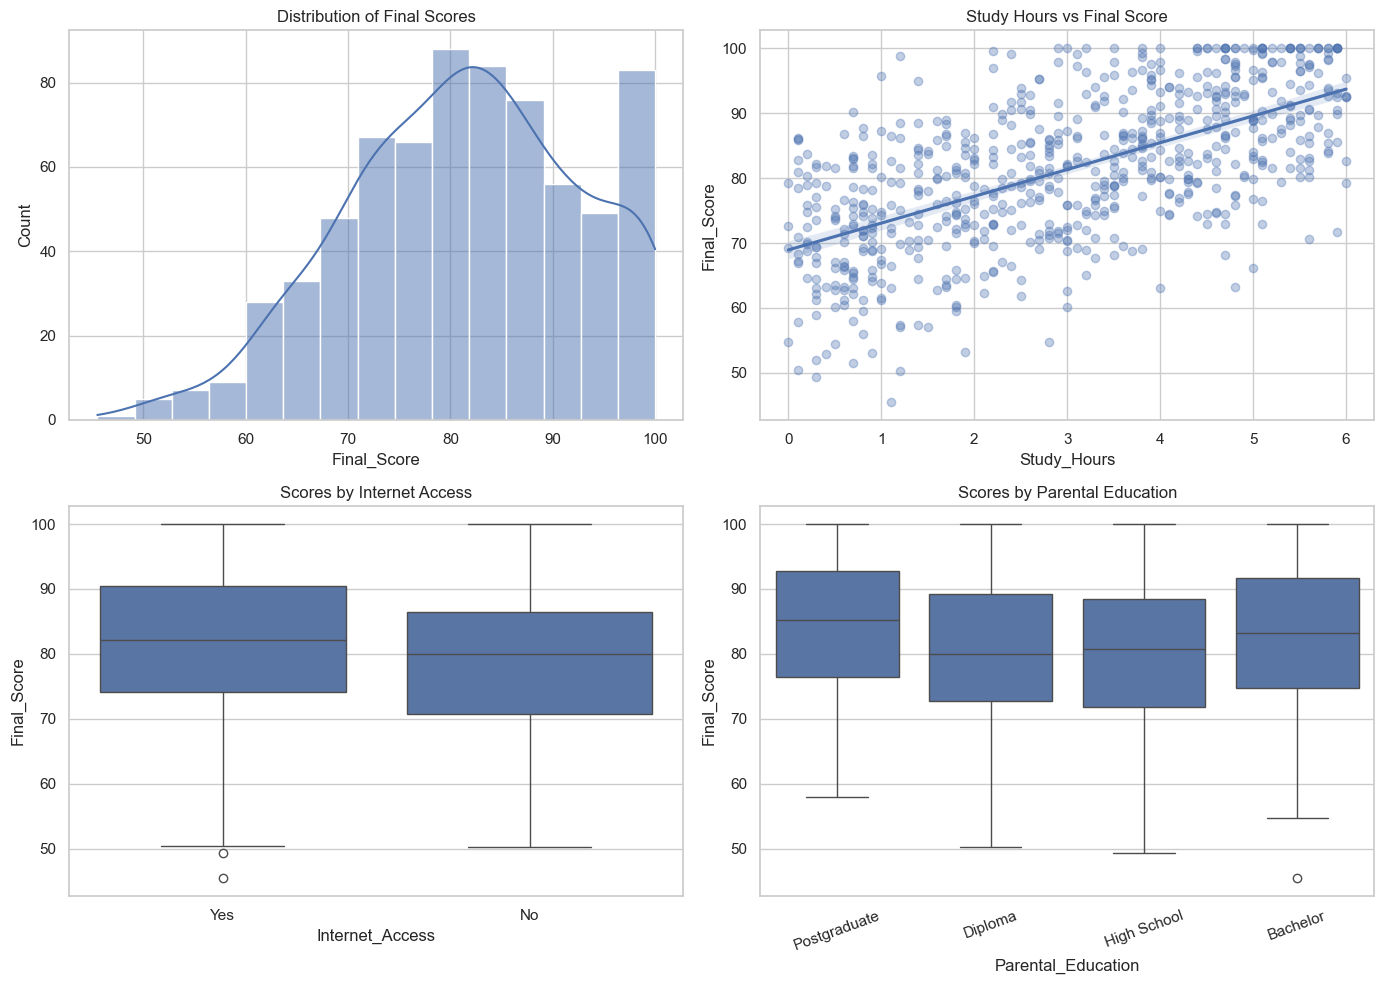

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sns.histplot(students["Final_Score"], kde=True, ax=axes[0,0])
axes[0,0].set_title("Distribution of Final Scores")
sns.regplot(data=students, x="Study_Hours", y="Final_Score", scatter_kws={"alpha":.35}, ax=axes[0,1])
axes[0,1].set_title("Study Hours vs Final Score")
sns.boxplot(data=students, x="Internet_Access", y="Final_Score", ax=axes[1,0])
axes[1,0].set_title("Scores by Internet Access")
sns.boxplot(data=students, x="Parental_Education", y="Final_Score", ax=axes[1,1])
axes[1,1].tick_params(axis="x", rotation=20)
axes[1,1].set_title("Scores by Parental Education")
plt.tight_layout()
plt.show()

## 3. Correlation and group comparisons

,mean,median,count
Extracurricular,,,
No,79.34,79.2,281
Yes,82.75,82.9,419


,mean,median,count
Internet_Access,,,
No,79.2,80.05,114
Yes,81.8,82.10,586


Parental_Education
Postgraduate    83.88
Bachelor        82.67
Diploma         80.32
High School     79.73
Name: Final_Score, dtype: float64

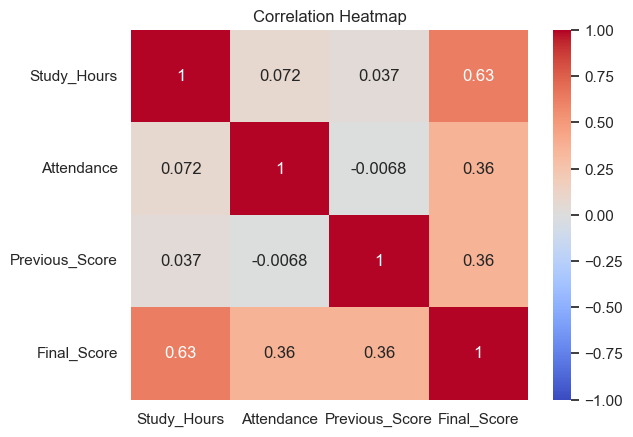

In [5]:
display(students.groupby("Extracurricular")["Final_Score"].agg(["mean","median","count"]).round(2))
display(students.groupby("Internet_Access")["Final_Score"].agg(["mean","median","count"]).round(2))
display(students.groupby("Parental_Education")["Final_Score"].mean().sort_values(ascending=False).round(2))
numeric_corr = students[["Study_Hours","Attendance","Previous_Score","Final_Score"]].corr()
sns.heatmap(numeric_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap")
plt.show()

## 4. Prepare data and compare regression models

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = students.drop(columns="Final_Score")
y = students["Final_Score"]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=180, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}
results = []
fitted = {}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"Model":name, "MAE":mean_absolute_error(y_test,pred),
                    "RMSE":mean_squared_error(y_test,pred)**0.5, "R2":r2_score(y_test,pred)})
    fitted[name] = pipe
results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(3))

,Model,MAE,RMSE,R2
1,Ridge Regression,5.713,7.258,0.602
0,Linear Regression,5.714,7.260,0.602
2,Random Forest,6.020,7.565,0.568
3,Gradient Boosting,5.997,7.589,0.565


## 5. Important factors and conclusion

Best model by RMSE: Ridge Regression
Lower MAE/RMSE and higher R² generally indicate better predictions.


,Permutation Importance
Study_Hours,3.578530
Previous_Score,1.733967
Attendance,1.699796
Parental_Education,0.342114
Extracurricular,0.079379
Internet_Access,-0.065239


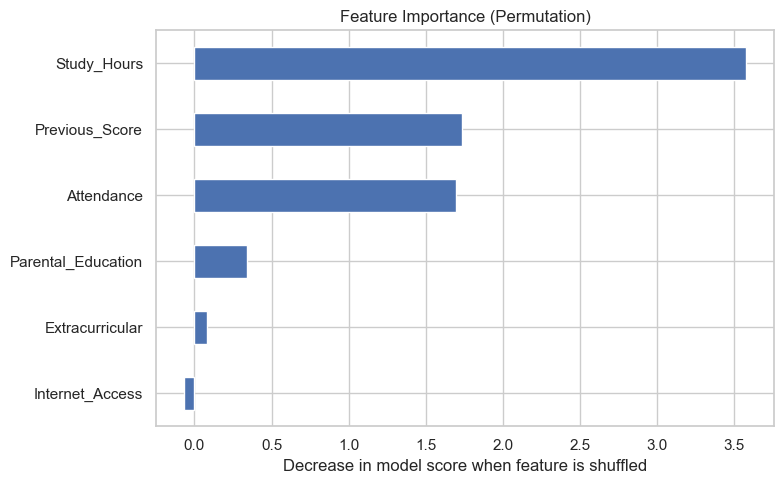

Conclusion: interpret the model metrics and importance chart together. These are synthetic data patterns, not evidence of causal effects in real students.


In [7]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name]
print("Best model by RMSE:", best_name)
print("Lower MAE/RMSE and higher R² generally indicate better predictions.")
# Permutation importance works for any fitted pipeline and preserves categorical preprocessing.
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test, y_test, n_repeats=8, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
display(importance.sort_values(ascending=False).to_frame("Permutation Importance"))
importance.plot(kind="barh", figsize=(8,5), title="Feature Importance (Permutation)")
plt.xlabel("Decrease in model score when feature is shuffled")
plt.tight_layout()
plt.show()
print("Conclusion: interpret the model metrics and importance chart together. These are synthetic data patterns, not evidence of causal effects in real students.")